# TUGAS 3 — PRAKTIK DAN PENGEMBANGAN AI RECIPE UNTUK GEOFISIKA

**Nama:** Andi Muhammad Syathir Ihwan

**NIM:** H061251065

**Mata Kuliah:** Kecerdasan Artifisial Geofisika

---

## Pendahuluan

AI Recipe merupakan panduan kerja terstruktur untuk menyelesaikan suatu permasalahan menggunakan bantuan kecerdasan artifisial.
Pada tugas ini dilakukan praktik recipe dari buku *AI Cookbook untuk Earth Sciences* serta pengembangan recipe baru yang berkaitan dengan bidang geofisika.
Tujuan tugas ini adalah memahami penyusunan recipe, penerapan kode Python, pemeriksaan hasil, dan dokumentasi proses analisis.

# BAGIAN I — RECIPE DARI BUKU

## Recipe 1: Audit Station CSV (R-IO-001)

### A. Problem


Recipe ini bertujuan memeriksa kualitas data pengamatan stasiun dalam format CSV sebelum digunakan untuk analisis lebih lanjut.

Pemeriksaan dilakukan terhadap struktur kolom, nilai kosong, rentang waktu pengamatan, dan timestamp duplikat.

### B. Minimal Theory

Quality Assurance dan Quality Control (QA/QC) merupakan proses pemeriksaan kualitas data untuk mengidentifikasi kesalahan atau ketidaksesuaian.

Dalam pengolahan data geofisika, pemeriksaan kualitas data penting dilakukan agar kesalahan pada data tidak memengaruhi hasil analisis.

### C. Input dan Constraints

**Input:**
- File CSV: `station-example.csv`
- Kolom waktu: `time`
- Kolom stasiun: `station_id`
- Kolom temperatur: `temperature_c`
- Kolom curah hujan: `rainfall_mm`

**Constraints:**
- File sumber tidak boleh diubah.
- Nilai kosong dan timestamp duplikat harus dilaporkan.
- Pemeriksaan dibatasi pada kualitas data dan statistik deskriptif.

### D. Prompt dan Procedure

**Prompt dokumentasi:**

> Buat recipe untuk melakukan audit kualitas data CSV stasiun pengamatan menggunakan Python dan pandas. Periksa jumlah baris dan kolom, tipe data, nilai kosong, rentang waktu, timestamp duplikat, serta statistik deskriptif. Jangan mengubah data sumber dan sajikan hasil pemeriksaan dalam laporan Markdown.

*Prompt di atas merupakan rumusan dokumentasi praktik, bukan kutipan langsung dari buku.*

**Procedure:**

1. Membaca data CSV menggunakan Python.
2. Memeriksa struktur dan tipe data setiap kolom.
3. Mengidentifikasi nilai yang hilang.
4. Memeriksa rentang waktu pengamatan.
5. Mengidentifikasi timestamp duplikat.
6. Menghitung statistik deskriptif.
7. Menampilkan hasil pemeriksaan.

### E. Code / Implementation

Recipe ini menggunakan program `r-io-001.py` dari bahan pendamping buku *AI Cookbook untuk Earth Sciences*.

Program asli telah berhasil dijalankan melalui terminal VS Code menggunakan Python 3.13.11 dan pandas 3.0.0.

Pada notebook ini dilakukan pemeriksaan ulang terhadap data contoh yang sama untuk menampilkan hasil analisis secara langsung.

In [1]:
import pandas as pd
from io import StringIO

# Data contoh dari recipe R-IO-001
data_csv = """time,station_id,temperature_c,rainfall_mm
2026-01-01T00:00:00Z,STA001,25.2,0.0
2026-01-01T01:00:00Z,STA001,24.8,0.0
2026-01-01T02:00:00Z,STA001,,1.2
2026-01-01T02:00:00Z,STA001,24.1,1.1
2026-01-01T04:00:00Z,STA001,23.7,0.3
"""

# Membaca data CSV
data = pd.read_csv(StringIO(data_csv))

# Menampilkan tabel
display(data)

,time,station_id,temperature_c,rainfall_mm
0,2026-01-01T00:00:00Z,STA001,25.2,0.0
1,2026-01-01T01:00:00Z,STA001,24.8,0.0
2,2026-01-01T02:00:00Z,STA001,NaN,1.2
3,2026-01-01T02:00:00Z,STA001,24.1,1.1
4,2026-01-01T04:00:00Z,STA001,23.7,0.3


In [2]:
# Pemeriksaan kualitas data stasiun

print("HASIL AUDIT DATA STASIUN")
print("-------------------------")

print("Jumlah baris:", len(data))
print("Jumlah kolom:", len(data.columns))
print("Jumlah stasiun unik:", data["station_id"].nunique())

print("\nNilai kosong setiap kolom:")
print(data.isna().sum())

print("\nTimestamp duplikat:", data["time"].duplicated().sum())

print("\nStatistik deskriptif:")
display(data[["temperature_c", "rainfall_mm"]].describe())

HASIL AUDIT DATA STASIUN
-------------------------
Jumlah baris: 5
Jumlah kolom: 4
Jumlah stasiun unik: 1

Nilai kosong setiap kolom:
time             0
station_id       0
temperature_c    1
rainfall_mm      0
dtype: int64

Timestamp duplikat: 1

Statistik deskriptif:


,temperature_c,rainfall_mm
count,4.000000,5.000000
mean,24.450000,0.520000
std,0.675771,0.589067
min,23.700000,0.000000
25%,24.000000,0.000000
50%,24.450000,0.300000
75%,24.900000,1.100000
max,25.200000,1.200000


### F. Result

Recipe R-IO-001 berhasil dijalankan menggunakan Python dan pandas.

Hasil pemeriksaan data CSV menunjukkan:

| Parameter | Hasil |
|---|---|
| Jumlah baris | 5 |
| Jumlah kolom | 4 |
| Jumlah stasiun unik | 1 |
| Nilai temperatur kosong | 1 |
| Nilai curah hujan kosong | 0 |
| Timestamp duplikat | 1 |
| Rata-rata temperatur | 24,45 °C |
| Rata-rata curah hujan | 0,52 mm |

Program asli dari buku juga telah menghasilkan laporan `station-summary.md`.

### G. Optional Check / Evidence

Hasil pemeriksaan menunjukkan bahwa jumlah baris dan kolom sesuai dengan data sumber.

Ditemukan satu nilai temperatur kosong dan satu timestamp duplikat. Nilai rata-rata temperatur dihitung dari empat pengamatan valid, sedangkan rata-rata curah hujan dihitung dari lima pengamatan.

**Kesimpulan Recipe 1:**

Recipe Audit Station CSV berhasil digunakan untuk memeriksa kualitas data pengamatan stasiun. Hasil menunjukkan bahwa data masih memiliki nilai kosong dan timestamp duplikat yang perlu diperhatikan sebelum dilakukan analisis lebih lanjut.

**Status Eksekusi: Executed — Berhasil.**

---

# BAGIAN II RECIPE BUATAN SENDIRI

## Recipe: Analisis Kecepatan Gelombang Seismik (R-SEIS-001)

### Pendahuluan

AI Recipe merupakan panduan kerja terstruktur yang digunakan untuk menyelesaikan suatu permasalahan dengan bantuan kecerdasan artifisial.

Dalam bidang geofisika, Python dapat digunakan untuk membantu proses pengolahan data, perhitungan parameter fisika, dan visualisasi hasil analisis.

Pada recipe ini dilakukan analisis sederhana untuk menghitung kecepatan gelombang seismik berdasarkan data jarak dan waktu tempuh.

Tujuan recipe ini adalah memahami hubungan antara jarak, waktu tempuh, dan kecepatan gelombang seismik menggunakan Python.

### A. Problem

Gelombang seismik merupakan gelombang elastis yang merambat melalui medium bumi.

Dalam analisis seismik, kecepatan gelombang menjadi salah satu parameter penting untuk memahami sifat medium bawah permukaan.

Kecepatan gelombang dapat dihitung apabila jarak tempuh dan waktu perambatannya diketahui.

Recipe ini bertujuan untuk:

1. Menghitung kecepatan gelombang seismik berdasarkan jarak dan waktu tempuh.
2. Menentukan kecepatan rata-rata gelombang.
3. Menampilkan hubungan jarak dan waktu tempuh dalam bentuk grafik.
4. Memeriksa kesesuaian hasil perhitungan Python dengan perhitungan manual.

### B. Minimal Theory

Kecepatan gelombang seismik merupakan jarak yang ditempuh gelombang setiap satuan waktu.

Secara matematis, kecepatan dapat dihitung menggunakan persamaan:

$$
v = \frac{s}{t}
$$

Keterangan:

- $v$ = kecepatan gelombang (km/s)
- $s$ = jarak tempuh gelombang (km)
- $t$ = waktu tempuh gelombang (s)

Apabila gelombang merambat melalui medium homogen dengan kecepatan konstan, maka hubungan antara jarak dan waktu tempuh bersifat linear.

Semakin besar jarak yang ditempuh gelombang, semakin lama waktu yang diperlukan untuk mencapai titik pengamatan.

### C. Input dan Constraints

**Input:**

Data yang digunakan merupakan data sintetis berupa jarak dan waktu tempuh gelombang seismik.

| Jarak (km) | Waktu Tempuh (s) |
|---|---|
| 10 | 2 |
| 20 | 4 |
| 30 | 6 |
| 40 | 8 |
| 50 | 10 |

**Constraints:**

- Data merupakan data sintetis, bukan hasil pengamatan lapangan.
- Jarak dinyatakan dalam kilometer (km).
- Waktu tempuh dinyatakan dalam detik (s).
- Kecepatan gelombang dinyatakan dalam km/s.
- Medium diasumsikan homogen.
- Kecepatan gelombang diasumsikan konstan.
- Pengaruh pemantulan, pembiasan, dan perubahan sifat lapisan bumi tidak diperhitungkan.

### D. Prompt dan Procedure

**Prompt AI:**

> Buat program Python untuk menghitung kecepatan gelombang seismik berdasarkan data jarak dan waktu tempuh. Gunakan pandas untuk membuat tabel data, numpy untuk menghitung kecepatan rata-rata, dan matplotlib untuk menampilkan grafik hubungan jarak terhadap waktu tempuh. Gunakan data sintetis dan tambahkan pemeriksaan hasil menggunakan perhitungan manual.

**Procedure:**

1. Menyiapkan data jarak dan waktu tempuh gelombang seismik.
2. Mengimpor library pandas, numpy, dan matplotlib.
3. Menyusun data dalam bentuk tabel.
4. Menghitung kecepatan gelombang menggunakan rumus kecepatan.
5. Menghitung kecepatan rata-rata.
6. Membuat grafik hubungan jarak dan waktu tempuh.
7. Memeriksa hasil menggunakan perhitungan manual.

### E. Code / Implementation

Implementasi recipe dilakukan menggunakan bahasa pemrograman Python dengan library:

- `pandas` untuk menyusun dan menampilkan data.
- `numpy` untuk menghitung kecepatan rata-rata.
- `matplotlib` untuk membuat grafik.

Kode program ditampilkan pada sel berikut.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data sintetis
jarak = [10, 20, 30, 40, 50]
waktu = [2, 4, 6, 8, 10]

# Membuat tabel data
data_seismik = pd.DataFrame({
    "Jarak (km)": jarak,
    "Waktu Tempuh (s)": waktu
})

# Menghitung kecepatan gelombang
data_seismik["Kecepatan (km/s)"] = (
    data_seismik["Jarak (km)"] /
    data_seismik["Waktu Tempuh (s)"]
)

# Menghitung kecepatan rata-rata
kecepatan_rata = np.mean(
    data_seismik["Kecepatan (km/s)"]
)

# Menampilkan hasil
print("HASIL ANALISIS KECEPATAN GELOMBANG SEISMIK")
print("-----------------------------------------")
print(f"Kecepatan rata-rata = {kecepatan_rata:.2f} km/s")

display(data_seismik)

HASIL ANALISIS KECEPATAN GELOMBANG SEISMIK
-----------------------------------------
Kecepatan rata-rata = 5.00 km/s


,Jarak (km),Waktu Tempuh (s),Kecepatan (km/s)
0,10,2,5.0
1,20,4,5.0
2,30,6,5.0
3,40,8,5.0
4,50,10,5.0


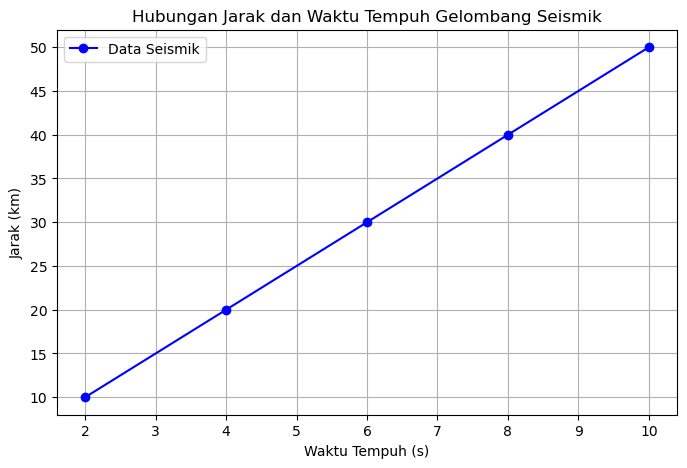

In [4]:
# Membuat grafik hubungan jarak dan waktu tempuh

plt.figure(figsize=(8, 5))

plt.plot(
    waktu,
    jarak,
    marker="o",
    linestyle="-",
    color="blue",
    label="Data Seismik"
)

plt.xlabel("Waktu Tempuh (s)")
plt.ylabel("Jarak (km)")
plt.title("Hubungan Jarak dan Waktu Tempuh Gelombang Seismik")

plt.grid(True)
plt.legend()

plt.show()

In [5]:
# Pemeriksaan menggunakan perhitungan manual

jarak_manual = 50
waktu_manual = 10

# Menghitung kecepatan manual
kecepatan_manual = jarak_manual / waktu_manual

print("PEMERIKSAAN HASIL")
print("-----------------")

print(f"Kecepatan Python = {kecepatan_rata:.2f} km/s")
print(f"Kecepatan Manual = {kecepatan_manual:.2f} km/s")

# Memeriksa kesesuaian hasil
assert np.isclose(kecepatan_rata, kecepatan_manual)

print("Hasil perhitungan sesuai.")

PEMERIKSAAN HASIL
-----------------
Kecepatan Python = 5.00 km/s
Kecepatan Manual = 5.00 km/s
Hasil perhitungan sesuai.


### F. Result

Program analisis kecepatan gelombang seismik menggunakan Python dengan data jarak dan waktu tempuh sintetis.

Berdasarkan perhitungan, diperoleh hasil sebagai berikut:

| Parameter | Hasil |
|---|---|
| Jarak minimum | 10 km |
| Jarak maksimum | 50 km |
| Waktu tempuh minimum | 2 s |
| Waktu tempuh maksimum | 10 s |
| Kecepatan minimum | 5 km/s |
| Kecepatan maksimum | 5 km/s |
| Kecepatan rata-rata | 5 km/s |

Hasil perhitungan menunjukkan bahwa kecepatan gelombang seismik pada data sintetis adalah 5 km/s.

Grafik memperlihatkan hubungan linear antara jarak dan waktu tempuh.

Hal ini menunjukkan bahwa pada medium homogen dengan kecepatan konstan, waktu tempuh gelombang meningkat seiring bertambahnya jarak.

### G. Optional Check / Evidence

Pemeriksaan dilakukan dengan membandingkan hasil perhitungan Python dan perhitungan manual.

**Diketahui:**

- Jarak tempuh = 50 km
- Waktu tempuh = 10 s

**Ditanya:**

Kecepatan gelombang seismik?

**Penyelesaian:**

Rumus kecepatan gelombang:

$$
v = \frac{s}{t}
$$

Substitusi nilai:

$$
v = \frac{50}{10}
$$

$$
v = 5 \text{ km/s}
$$

Hasil perhitungan manual menunjukkan kecepatan sebesar 5 km/s.

Nilai tersebut sesuai dengan hasil perhitungan Python.

Dengan demikian, program berhasil menghitung kecepatan gelombang seismik berdasarkan data sintetis yang digunakan.

---

# KESIMPULAN

Berdasarkan pelaksanaan Recipe Analisis Kecepatan Gelombang Seismik, dapat disimpulkan bahwa:

1. Python dapat digunakan untuk menghitung kecepatan gelombang seismik berdasarkan data jarak dan waktu tempuh.

2. Berdasarkan data sintetis, diperoleh kecepatan gelombang seismik sebesar 5 km/s.

3. Grafik menunjukkan hubungan linear antara jarak dan waktu tempuh gelombang.

4. Hasil perhitungan Python sesuai dengan hasil perhitungan manual.

5. Recipe ini menunjukkan penerapan Python untuk membantu analisis sederhana dalam bidang seismologi.

Hasil yang diperoleh merupakan demonstrasi menggunakan data sintetis dan tidak menggambarkan kondisi bawah permukaan suatu wilayah tertentu.

**Status Eksekusi: Executed — Berhasil.**